# Currents and voltages
Contact current transients, impact ionization, I-V and spectra.
Figures are saved in `SAVE_DIR` as `.png`, `.pdf` and editable `.mplfig`
(reopen with `python open_fig.py <file>.mplfig` or `mcplot.load_figure`).
Plotting functions are in `transient_plots.py`.

In [1]:
# Interactive figures (zoom/pan) need ipympl; otherwise fall back to static figures
try:
    import ipympl  # noqa: F401
    get_ipython().run_line_magic("matplotlib", "widget")
except ImportError:
    get_ipython().run_line_magic("matplotlib", "inline")
import os

import matplotlib.pyplot as plt
import numpy as np
import transient_plots as tp
from mcplot import save_figure, set_style

set_style(25)

SAVE_FIGURES = True  # save every figure as .png, .pdf and editable .mplfig
SAVE_DIR = "output/currents_and_voltages"


def save(fig, name):
    """Save fig as SAVE_DIR/name.{png,pdf,mplfig} (reopen the .mplfig with open_fig.py)."""
    if SAVE_FIGURES:
        save_figure(fig, os.path.join(SAVE_DIR, name), formats=("png", "pdf"), dpi=300, bbox_inches="tight")

# Current and voltage
SPAD current, quenching voltage $V_q$ and SPAD voltage drop $V_d = V_{bias} - V_q$.

In [5]:
base_path = "/home/angelo/server/csmhome2/amudano/MonteCarlo/DEMC/SPAD_FBK_v2/quasi_1D"
folder_list = ["CONTINUE/deep_implant_1.0/1SC/quenching--37.00V_inj_on_top"]
# folder_list = ["10um/vg/MC/1SC/voltage_ramp--37.00V_try_blandmesh"]
# folder_list = ["4um/CONTINUE/1SC/quenching--37.00V_5ns_R150k_C5f"]
label_list = ["Continue"]

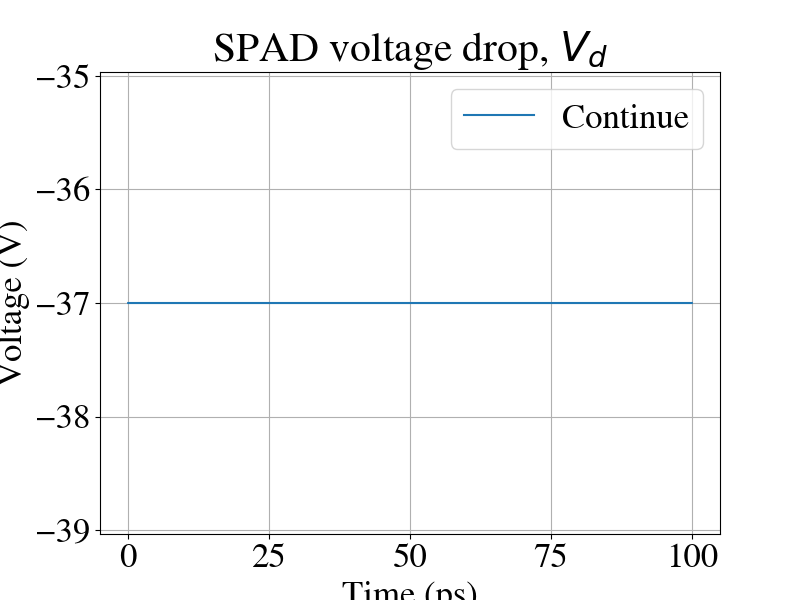

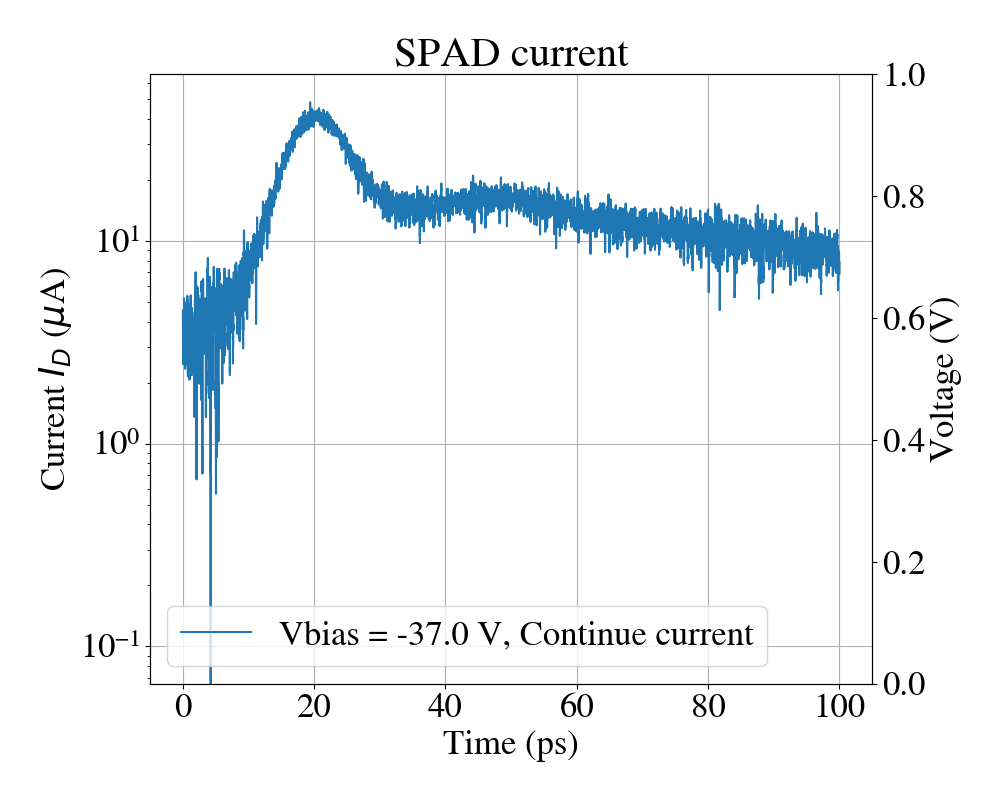

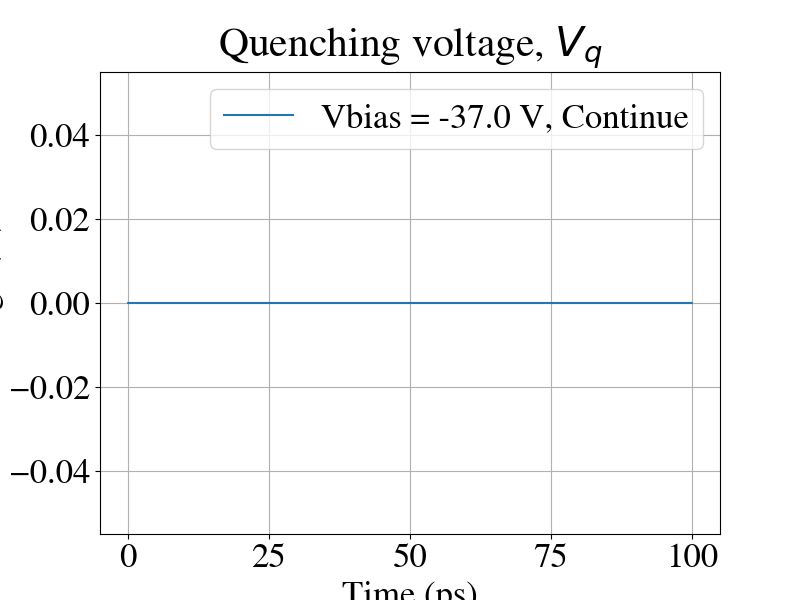

In [3]:
plt.close("all")
fig_i, fig_vq, fig_vd = tp.current_and_voltage_figures(base_path, folder_list, label_list, contact="ncontact",
                                                       voltage_on_twin=False)
save(fig_i, "spad_current")
save(fig_vq, "quenching_voltage")
save(fig_vd, "voltage_drop")
plt.show()

# Impact ionization
## Current and impact ionization events

In [4]:
base_path = "/home/angelo/mnt/server/MonteCarlo/DEMC/SPAD_FBK_v2/3D"
folder_list = ["4um/CONTINUE/1SC/quenching--37.00V_3ns"]
# folder_list = ["4um/CONTINUE/1SC/quenching--37.00V_1ns_R100k_C5f", "4um/CONTINUE/1SC/quenching--37.00V_1ns_R150k_C5f"]
label_list = ["32", "37"]

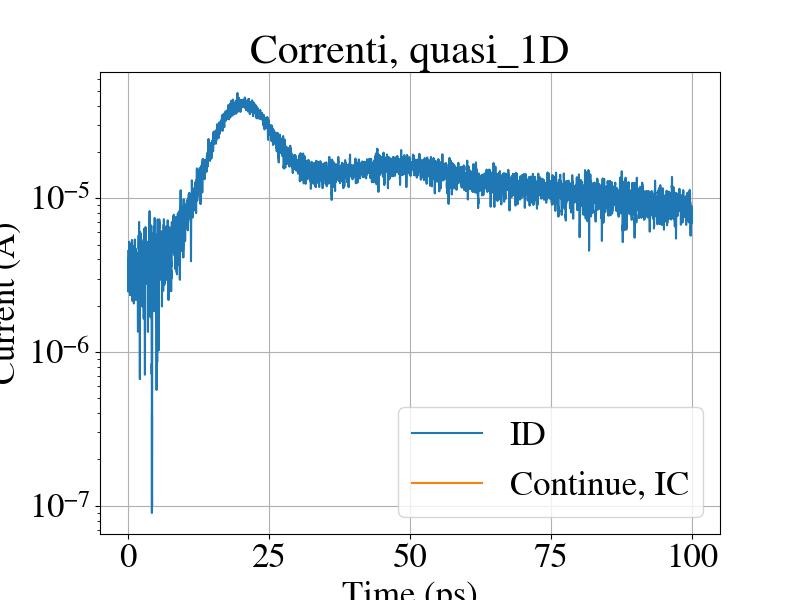

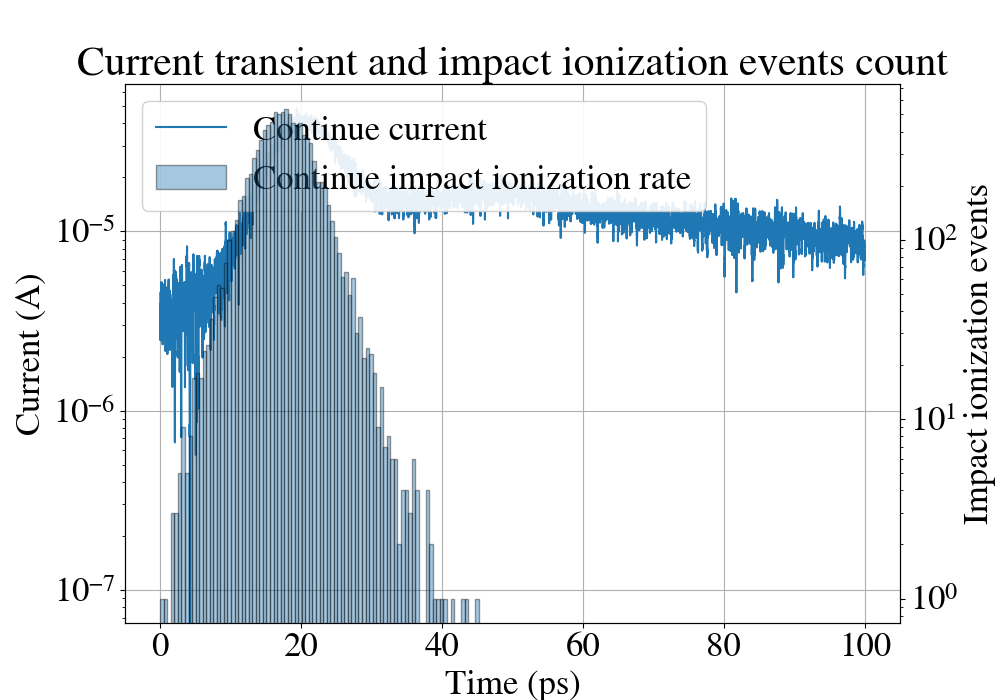

In [6]:
plt.close("all")
fig = tp.current_and_ionization_figure(base_path, folder_list, label_list, contact="ncontact", figsize=(10, 7))
save(fig, "current_and_ionization")
fig = tp.diode_and_capacitive_current_figure(base_path, folder_list, label_list, contact="ncontact",
                                             legend_loc="lower right")
save(fig, "diode_and_capacitive_current")
plt.show()

## Impact ionization events

In [ ]:
base_path = "/home/angelo/mnt/server/MonteCarlo/DEMC/SPAD_FBK_v2/quasi_1D"
folder_list = ["FF/deep_implant_1.0/breakdown--40.00V-s999"]
# bias = [-37]
# folder_list = [f"MC/new_mesh/voltage_ramp-1fs-{v:.2f}V" for v in bias]
label_list = ["continue", "no full contact"]
t_stop = 150e-12  # histogram range: [0, t_stop]

In [ ]:
plt.close("all")
fig = tp.ionization_events_figure(base_path, folder_list, label_list, t_stop, figsize=(15, 7))
save(fig, "ionization_events")
plt.show()

# I-V characteristic
Mean of the last 10 current samples of every voltage-ramp simulation.

In [ ]:
set_style(15)
base_path = "/mnt/polmcad/MonteCarlo/DEMC/SPAD_FBK_v2/3D/MC"
bias = np.linspace(-35, -15, 21)

In [ ]:
plt.close("all")
fig = tp.iv_figure(base_path, bias, folder_fmt="voltage_ramp-{v:.2f}V", contact="pcontact")
save(fig, "iv_characteristic")
plt.show()

# Current transient

In [ ]:
base_path = "/home/angelo/mnt/server/MonteCarlo/DEMC/SPAD_FBK_v2/no_epi"
folder_list = ["FF/3D/avalanche_m37", "FF/3D/avalanche_m32"]
# bias = np.linspace(-30, -40, 11)
# folder_list = [f"MC/equal_doping/voltage_ramp-{v:.2f}V" for v in bias]
label_list = ["37", "32", "active bulk"]

In [ ]:
plt.close("all")
fig = tp.current_transient_figure(base_path, folder_list, label_list, contact="ncontact", figsize=(10, 7),
                                  log=True, legend_loc="upper right")
save(fig, "current_transient")
plt.show()

## Savitzky-Golay filtered current

In [ ]:
window_length = 101  # must be odd
polyorder = 3

In [ ]:
plt.close("all")
fig = tp.current_transient_figure(base_path, folder_list, label_list, contact="pcontact", figsize=(8, 6),
                                  log=False, legend_loc="lower left", sv_filter=(window_length, polyorder))
save(fig, "current_transient_sv_filter")
plt.show()

## Current spectrum (FFT)
Uses the folders of the *Current transient* section. Valid only for constant dt.

In [ ]:
plt.close("all")
fig = tp.current_fft_figure(base_path, folder_list, label_list, contact="p-contact")
save(fig, "current_fft")
plt.show()

# Scattering rate

In [ ]:
path = "/mnt/polmcad/MonteCarlo/Materials/silicon_mio/scattering/Energy_Rates"
scattering_file = f"{path}/e_acoabs_TA_band_5_band_5.txt"

In [ ]:
plt.close("all")
fig = tp.scattering_rate_figure(scattering_file, xlim=(0, 4))
save(fig, "scattering_rate")
plt.show()